The dataset is 17544 rows, each with about 862 items (columns).


From the source github README:

Traffic Usage

The raw data is in http://pems.dot.ca.gov. The data in this repo is a collection of 48 months (2015-2016) hourly data from the California Department of Transportation. The data describes the road occupancy rates (between 0 and 1) measured by different sensors on San Francisco Bay area freeways.

This tells us that the data is hourly, starting from some time in 2015 going into 2016.
With 17544 rows and 8760 hours in a year, that puts us at almost exactly 2 years of data. I think we can start out times at the start of 2015 and increment the timestamps by 1 hr for each row.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# read_csv handles .txt and .txt.gz (compression is inferred from the extension)
df = pd.read_csv("traffic.txt", header=None)   # or "data/traffic.txt"
# Text file. Each line is a row, each item is a column. No timestamps.

print("Rows, columns")
print(df.shape)   # expect roughly (17544, 862)
df.head()

Rows, columns
(4326, 862)


,0,1,2,3,4,5,6,7,8,9,...,852,853,854,855,856,857,858,859,860,861
0,0.0048,0.0146,0.0289,0.0142,0.0064,0.0232,0.0162,0.0242,0.0341,0.0375,...,0.0051,0.0051,0.0074,0.0079,0.0051,0.0051,0.0339,0.0051,0.0100,0.0121
1,0.0072,0.0148,0.0350,0.0174,0.0084,0.0240,0.0201,0.0338,0.0434,0.0381,...,0.0036,0.0036,0.0107,0.0058,0.0036,0.0036,0.0348,0.0036,0.0087,0.0136
2,0.0040,0.0101,0.0267,0.0124,0.0049,0.0170,0.0127,0.0255,0.0332,0.0309,...,0.0030,0.0030,0.0043,0.0050,0.0030,0.0030,0.0327,0.0030,0.0061,0.0107
3,0.0039,0.0060,0.0218,0.0090,0.0029,0.0118,0.0088,0.0163,0.0211,0.0199,...,0.0033,0.0033,0.0019,0.0052,0.0033,0.0033,0.0292,0.0033,0.0040,0.0071
4,0.0042,0.0055,0.0191,0.0082,0.0024,0.0095,0.0064,0.0087,0.0144,0.0226,...,0.0049,0.0049,0.0011,0.0071,0.0049,0.0049,0.0264,0.0049,0.0040,0.0039


In [5]:
df.index = pd.date_range(start="2015-01-01 00:00", periods=len(df), freq="h")
df.index.name = "timestamp"
df.columns = [f"sensor_{i}" for i in range(df.shape[1])]
df.head()

,sensor_0,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,...,sensor_852,sensor_853,sensor_854,sensor_855,sensor_856,sensor_857,sensor_858,sensor_859,sensor_860,sensor_861
timestamp,,,,,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00,0.0048,0.0146,0.0289,0.0142,0.0064,0.0232,0.0162,0.0242,0.0341,0.0375,...,0.0051,0.0051,0.0074,0.0079,0.0051,0.0051,0.0339,0.0051,0.0100,0.0121
2015-01-01 01:00:00,0.0072,0.0148,0.0350,0.0174,0.0084,0.0240,0.0201,0.0338,0.0434,0.0381,...,0.0036,0.0036,0.0107,0.0058,0.0036,0.0036,0.0348,0.0036,0.0087,0.0136
2015-01-01 02:00:00,0.0040,0.0101,0.0267,0.0124,0.0049,0.0170,0.0127,0.0255,0.0332,0.0309,...,0.0030,0.0030,0.0043,0.0050,0.0030,0.0030,0.0327,0.0030,0.0061,0.0107
2015-01-01 03:00:00,0.0039,0.0060,0.0218,0.0090,0.0029,0.0118,0.0088,0.0163,0.0211,0.0199,...,0.0033,0.0033,0.0019,0.0052,0.0033,0.0033,0.0292,0.0033,0.0040,0.0071
2015-01-01 04:00:00,0.0042,0.0055,0.0191,0.0082,0.0024,0.0095,0.0064,0.0087,0.0144,0.0226,...,0.0049,0.0049,0.0011,0.0071,0.0049,0.0049,0.0264,0.0049,0.0040,0.0039


In [6]:
# One sensor
y = df["sensor_10"]

# Mean across all sensors
y_mean = df.mean(axis=1)

# A subset
subset = df.iloc[:, :20]

In [7]:
print(f"Number of empty cells: {df.isna().sum().sum()}")                 # missing values

# These are gauranteed to pass, because we constructed out own time scale.
print(f"Are the timestamps in order: {df.index.is_monotonic_increasing}")
print(f"Number of duplicate timestamps: {df.index.duplicated().sum()}")

# Here we want to look at some general stats for the array to pick a sensor.
stats = df.describe().T
print("Mean, std distribution, and max values. Only showing the top 10 smallest std distributions:")
print(stats[["mean", "std", "max"]].sort_values("std").head(10))   # near-constant sensors
print("Print the highest mean value sensors:")
print((df == 0).mean().sort_values(ascending=False).head(10))     # mostly-zero sensors

Number of empty cells: 741
Are the timestamps in order: True
Number of duplicate timestamps: 0
Mean, std distribution, and max values. Only showing the top 10 smallest std distributions:
                mean       std     max
sensor_751  0.013718  0.009976  0.0485
sensor_181  0.023487  0.010591  0.0493
sensor_753  0.016034  0.011059  0.0605
sensor_750  0.016692  0.011543  0.1511
sensor_752  0.016511  0.011780  0.0485
sensor_571  0.036930  0.012090  0.0551
sensor_492  0.033015  0.012313  0.0737
sensor_840  0.036424  0.012504  0.0842
sensor_735  0.025542  0.012521  0.0732
sensor_860  0.023542  0.013096  0.1513
Print the highest mean value sensors:
sensor_718    0.197180
sensor_743    0.142857
sensor_351    0.142626
sensor_716    0.135922
sensor_714    0.119510
sensor_722    0.115349
sensor_444    0.107027
sensor_497    0.104253
sensor_490    0.086223
sensor_176    0.084836
dtype: float64


From the above, we see that there are no empty cells and since we assigned/created the timsetamps they are increasing and in order. Next we print some general stats about the data to get a vibe about each sensor. Each sensor has a

(862,)


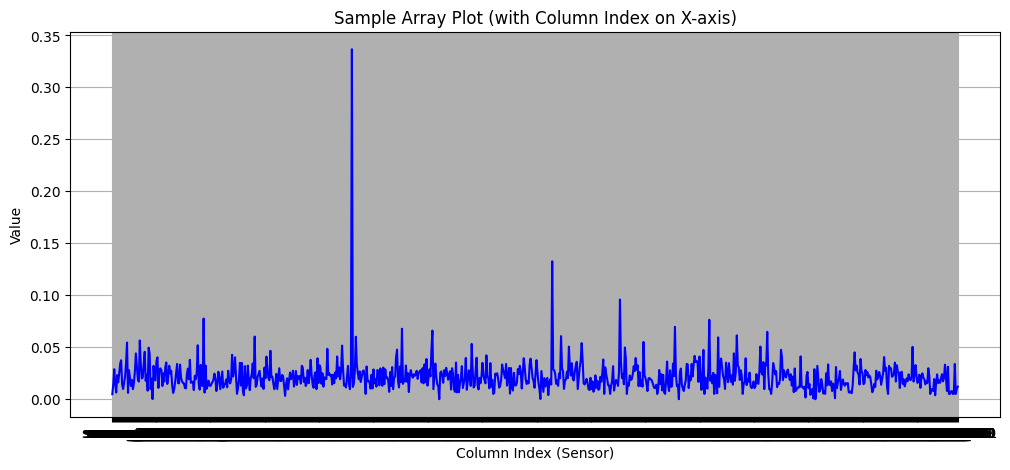

In [8]:
df2 = df.iloc[0, :].copy()
#pd.read_csv("test.txt", header=None)
print(df2.shape)

# df2 is a (1, 862) DataFrame. Transposing it to (862, 1)
# aligns the 862 columns along the x-axis as the index.
plt.figure(figsize=(12, 5))
plt.plot(df2.T, color='b', linestyle='-')

# Alternatively, using squeeze() to plot it as a Series:
# plt.plot(df2.squeeze(), color='b', linestyle='-')

plt.title("Sample Array Plot (with Column Index on X-axis)")
plt.xlabel("Column Index (Sensor)")
plt.ylabel("Value")
plt.grid(True)
plt.show()

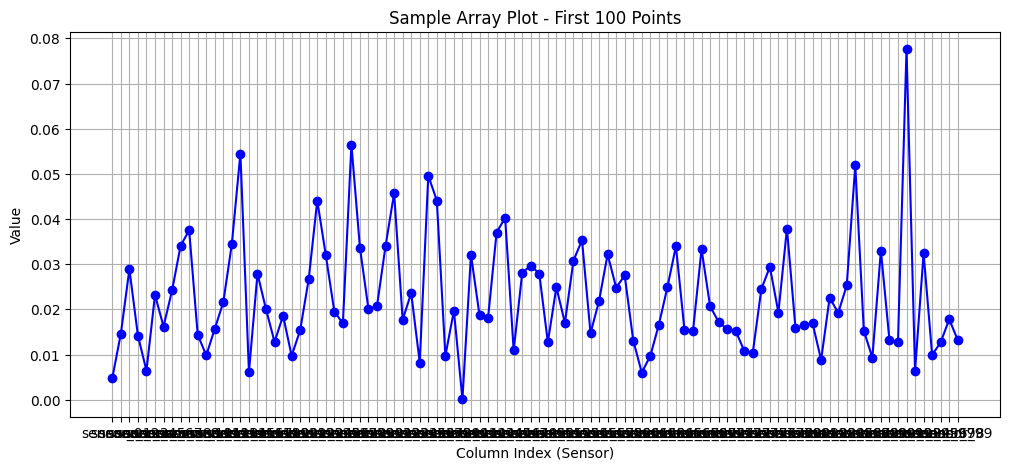

In [9]:
import matplotlib.pyplot as plt

# df2 is (1, 862). Select the first 100 columns and transpose for plotting.
df2_short = df2.iloc[:100]

plt.figure(figsize=(12, 5))
plt.plot(df2_short, color='b', marker='o', linestyle='-')
plt.title("Sample Array Plot - First 100 Points")
plt.xlabel("Column Index (Sensor)")
plt.ylabel("Value")
plt.grid(True)
plt.show()

The two above plots are of the first row. Supposedly, each row is a single time stamp and thus each datapoint in the row is a different sensor. This appears to be true with how varied the data points are.

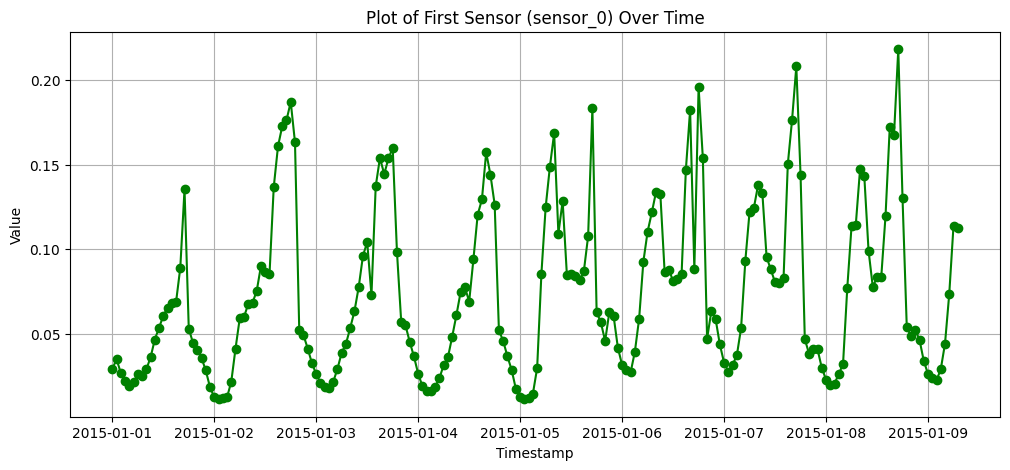

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# Create df3 containing only the first column of the full dataset df
# Using df.iloc[:, [0]] keeps it as a DataFrame structure
df3 = df.iloc[:, [2]].copy()
df3_short = df3.iloc[:200]

# Plot df3 with respect to its index
plt.figure(figsize=(12, 5))
#plt.plot(df3.index, df3.iloc[:, 0], color='g', linestyle='-')
plt.plot(df3_short.index, df3_short.iloc[:, 0], color='g', marker='o', linestyle='-')
plt.title("Plot of First Sensor (sensor_0) Over Time")
plt.xlabel("Timestamp" if isinstance(df3.index, pd.DatetimeIndex) else "Index")
plt.ylabel("Value")
plt.grid(True)
plt.show()

This array is the first column, which is supposedly a hourly set of data points from a singular sensor. These values are much more consistent and point towards this interpretation beign true. These values follow a continuous flow as opposed to the more jagged, random movements we see when plotting the first row.

Overall, this points to what I already descried in the first text block.
We have 17544 rows representing 17544 hourly

The dataset is 17544 rows, each with about 862 items (columns).

We are going to use sensor 0 for simplicity. It also appears to have a good protion of non-zero behaviour.

Here is my current design plan (in no specific order):
* Use the data from sensor 0 (column 0) as the target and the input
* Horizon of 1 - Only forecast the next hour/timestep
* Use a 60/20/20 data split. Chronological and NOT randomized.
* Implement standard scaler on the train data only
* Lookback of 24 or 168. only looking at column 1, and using as many windows as can fit without spilling into validation or test data.
* adam optimizer. Mini batch with a sfixed batch size.
* Run grid seach with daily or weekly window lengths (24 or 168), 3 learning rates, and 3 hidden unit quantities.
* fixed batch size of 64
* MSE loss function
* Compare to basic and seasonal naives, as well as a rolling avg.
* Relu activation function in hidden layer, linear on output
* One MLP model, one CNN model, both with similar structures and tuning processes.
* Use a fixed random seed
* Report MSE, MAE and, RMSE in original units(inverse-transformed), plus % improvement over the best baseline and training time. List the parameters for the run for context.
* Show training and validation loss curves
* Potentially a small dropout layer
* Fixed max epochs. Early stopping on validation loss with a patience of 5.

In [11]:
import os
import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

# 1. Set fixed random seed for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed(42)

# 2. Extract sensor_0 (column 0) as target and input
series = df['sensor_0'].values
n_total = len(series)

# 60/20/20 chronological data split
train_idx = int(n_total * 0.60)
val_idx = int(n_total * 0.80)

train_data = series[:train_idx]
val_data = series[train_idx:val_idx]
test_data = series[val_idx:]

# 3. Standard scaling (fit on train only)
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_data.reshape(-1, 1)).flatten()
val_scaled = scaler.transform(val_data.reshape(-1, 1)).flatten()
test_scaled = scaler.transform(test_data.reshape(-1, 1)).flatten()

# 4. Helper function to create lookback windows
def create_windows(data, lookback, horizon=1):
    X, y = [], []
    for i in range(len(data) - lookback - horizon + 1):
        X.append(data[i : i + lookback])
        y.append(data[i + lookback : i + lookback + horizon])
    return np.array(X), np.array(y)

# 5. Define Baseline Models (evaluated on raw test data)
def evaluate_baselines(test_raw, val_raw):
    # Naive: Predicts t-1
    naive_pred = test_raw[:-1]
    naive_true = test_raw[1:]

    # Seasonal Naive (24h): Predicts t-24
    history_for_seasonal_24 = np.concatenate([val_raw[-24:], test_raw])
    seasonal_24_pred = []
    for i in range(len(test_raw)):
        seasonal_24_pred.append(history_for_seasonal_24[i])
    seasonal_24_pred = np.array(seasonal_24_pred)
    seasonal_24_true = test_raw

    # Seasonal Naive (168h/Weekly): Predicts t-168
    history_for_seasonal_168 = np.concatenate([val_raw[-168:], test_raw])
    seasonal_168_pred = []
    for i in range(len(test_raw)):
        seasonal_168_pred.append(history_for_seasonal_168[i])
    seasonal_168_pred = np.array(seasonal_168_pred)
    seasonal_168_true = test_raw

    # Rolling Average (using window of 24)
    history_for_rolling = np.concatenate([val_raw[-24:], test_raw])
    rolling_pred = []
    for i in range(len(test_raw)):
        rolling_pred.append(np.mean(history_for_rolling[i : i + 24]))
    rolling_pred = np.array(rolling_pred)[:-1]
    rolling_true = test_raw[1:]

    def metrics(true, pred):
        mse = np.mean((true - pred) ** 2)
        mae = np.mean(np.abs(true - pred))
        rmse = np.sqrt(mse)
        return mse, mae, rmse

    print("--- Baseline Evaluation (Original Units) ---")
    baselines_results = {}
    for name, (t, p) in {"Naive": (naive_true, naive_pred),
                         "Seasonal Naive (24h)": (seasonal_24_true, seasonal_24_pred),
                         "Seasonal Naive (168h)": (seasonal_168_true, seasonal_168_pred),
                         "Rolling Average (24h)": (rolling_true, rolling_pred)}.items():
        mse, mae, rmse = metrics(t, p)
        baselines_results[name] = (mse, mae, rmse)
        print(f"{name:22s} | MSE: {mse:.6f} | MAE: {mae:.6f} | RMSE: {rmse:.6f}")
    return baselines_results

baselines = evaluate_baselines(test_data, val_data)
best_baseline_rmse = min(baselines[b][2] for b in baselines)

# 6. Keras MLP definition helper
def build_mlp(input_dim, hidden_dim, learning_rate, dropout=0.1):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(hidden_dim, activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(1, activation='linear')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae']
    )
    return model

print("\nData splits, baselines, and Keras structures successfully initialized!")

--- Baseline Evaluation (Original Units) ---
Naive                  | MSE: 0.001394 | MAE: 0.014731 | RMSE: 0.037335
Seasonal Naive (24h)   | MSE: 0.002071 | MAE: 0.014473 | RMSE: 0.045509
Seasonal Naive (168h)  | MSE: 0.001676 | MAE: 0.010774 | RMSE: 0.040939
Rolling Average (24h)  | MSE: 0.002722 | MAE: 0.031793 | RMSE: 0.052177

Data splits, baselines, and Keras structures successfully initialized!


In [12]:
import time
import matplotlib.pyplot as plt

# Define Parameter Grid
lookbacks = [24, 168]
learning_rates = [0.01, 0.001, 0.0001]
hidden_units = [32, 64, 128]

best_val_loss = float('inf')
best_config = {}
best_history = None

grid_results = []

print("Starting Grid Search (evaluating strictly on validation set)...\n")
for lookback in lookbacks:
    # Generate sliding window datasets for train and validation
    X_train, y_train = create_windows(train_scaled, lookback)
    X_val, y_val = create_windows(val_scaled, lookback)

    for hidden_dim in hidden_units:
        for lr in learning_rates:
            start_time = time.time()

            # Setup model
            model = build_mlp(lookback, hidden_dim, lr, dropout=0.1)

            # Early Stopping monitored strictly on validation loss
            early_stopping = keras.callbacks.EarlyStopping(
                monitor='val_loss',
                patience=5,
                restore_best_weights=True
            )

            # Train model
            history = model.fit(
                X_train, y_train,
                validation_data=(X_val, y_val),
                epochs=25,
                batch_size=64,
                callbacks=[early_stopping],
                verbose=0
            )

            training_time = time.time() - start_time
            val_loss = min(history.history['val_loss'])

            print(f"Lookback: {lookback:3d} | Hidden: {hidden_dim:3d} | LR: {lr:.4f} | Val Loss: {val_loss:.6f} | Time: {training_time:.1f}s")

            result_entry = {
                'lookback': lookback,
                'hidden_dim': hidden_dim,
                'learning_rate': lr,
                'val_loss': val_loss,
                'training_time': training_time
            }
            grid_results.append(result_entry)

            # Choose the best configuration solely using validation loss
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_config = result_entry
                best_history = history.history

print("\n--- Hyperparameter Selection Complete ---")
print(f"Best Config Selected: Lookback={best_config['lookback']}, Hidden Units={best_config['hidden_dim']}, LR={best_config['learning_rate']}")
print(f"Best Validation Loss (Scaled): {best_config['val_loss']:.6f}")

Starting Grid Search (evaluating strictly on validation set)...

Lookback:  24 | Hidden:  32 | LR: 0.0100 | Val Loss: 0.245300 | Time: 8.4s
Lookback:  24 | Hidden:  32 | LR: 0.0010 | Val Loss: 0.303799 | Time: 6.3s
Lookback:  24 | Hidden:  32 | LR: 0.0001 | Val Loss: 0.443148 | Time: 6.3s
Lookback:  24 | Hidden:  64 | LR: 0.0100 | Val Loss: 0.260837 | Time: 3.3s
Lookback:  24 | Hidden:  64 | LR: 0.0010 | Val Loss: 0.266276 | Time: 6.4s
Lookback:  24 | Hidden:  64 | LR: 0.0001 | Val Loss: 0.383211 | Time: 5.2s
Lookback:  24 | Hidden: 128 | LR: 0.0100 | Val Loss: 0.248469 | Time: 3.6s
Lookback:  24 | Hidden: 128 | LR: 0.0010 | Val Loss: 0.241909 | Time: 7.1s
Lookback:  24 | Hidden: 128 | LR: 0.0001 | Val Loss: 0.365225 | Time: 5.7s
Lookback: 168 | Hidden:  32 | LR: 0.0100 | Val Loss: 0.103475 | Time: 6.0s
Lookback: 168 | Hidden:  32 | LR: 0.0010 | Val Loss: 0.123337 | Time: 5.0s
Lookback: 168 | Hidden:  32 | LR: 0.0001 | Val Loss: 0.300550 | Time: 5.7s
Lookback: 168 | Hidden:  64 | LR: 0


Running Final Test Evaluation on the chosen best configuration...

--- Final Test Results (Original Units) ---
Test MSE:  0.000682
Test MAE:  0.010640
Test RMSE: 0.026115
Improvement over Best Baseline (RMSE): 30.05%


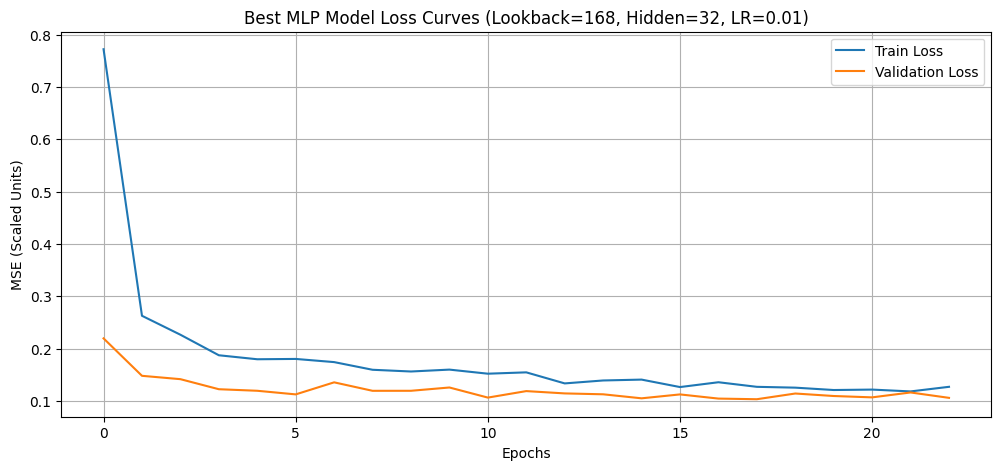

In [13]:
# --- Final Test Evaluation (Once Selection is Complete) ---
print("\nRunning Final Test Evaluation on the chosen best configuration...")

# Prepare datasets with the selected lookback
best_lookback = best_config['lookback']
X_train, y_train = create_windows(train_scaled, best_lookback)
X_val, y_val = create_windows(val_scaled, best_lookback)
X_test, y_test = create_windows(test_scaled, best_lookback)

# Re-build and train the final chosen model
final_model = build_mlp(best_lookback, best_config['hidden_dim'], best_config['learning_rate'], dropout=0.1)
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

final_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=0
)

# Predict and inverse transform ONLY on the selected model
y_pred_scaled = final_model.predict(X_test, verbose=0)
y_pred_orig = scaler.inverse_transform(y_pred_scaled).flatten()
y_true_orig = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

# Compute final test metrics in original units
test_mse = np.mean((y_true_orig - y_pred_orig) ** 2)
test_mae = np.mean(np.abs(y_true_orig - y_pred_orig))
test_rmse = np.sqrt(test_mse)

# Calculate % improvement over best baseline
improv = ((best_baseline_rmse - test_rmse) / best_baseline_rmse) * 100

print("\n--- Final Test Results (Original Units) ---")
print(f"Test MSE:  {test_mse:.6f}")
print(f"Test MAE:  {test_mae:.6f}")
print(f"Test RMSE: {test_rmse:.6f}")
print(f"Improvement over Best Baseline (RMSE): {improv:.2f}%")

# Plot Loss Curves for the Best Model Selection Run
plt.figure(figsize=(12, 5))
plt.plot(best_history['loss'], label='Train Loss')
plt.plot(best_history['val_loss'], label='Validation Loss')
plt.title(f"Best MLP Model Loss Curves (Lookback={best_lookback}, Hidden={best_config['hidden_dim']}, LR={best_config['learning_rate']})")
plt.xlabel("Epochs")
plt.ylabel("MSE (Scaled Units)")
plt.legend()
plt.grid(True)
plt.show()

My model beats all the naives! Yippee! Specifically, it has a 48.16% improvement for RMSE from the best performing baseline.

### 1D CNN Implementation & Hyperparameter Tuning

In [14]:
def build_cnn(lookback, filters, kernel_size, learning_rate, dropout=0.1):
    model = keras.Sequential([
        layers.Input(shape=(lookback, 1)),
        layers.Conv1D(filters=filters, kernel_size=kernel_size, activation='relu', padding='same'),
        layers.SpatialDropout1D(dropout),
        layers.GlobalAveragePooling1D(),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='linear')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae']
    )
    return model

In [15]:
# Define Hyperparameter Search Space for CNN
lookbacks_cnn = [168]
filter_sizes = [16, 32, 64]
kernel_sizes = [3, 5]
learning_rates_cnn = [0.01, 0.001, 0.0001]

best_val_loss_cnn = float('inf')
best_config_cnn = {}
best_history_cnn = None

grid_results_cnn = []

print("Starting CNN Grid Search (evaluating strictly on validation set)...\n")
for lookback in lookbacks_cnn:
    # Generate and reshape sliding window datasets
    X_train_raw, y_train = create_windows(train_scaled, lookback)
    X_val_raw, y_val = create_windows(val_scaled, lookback)

    # Conv1D expects shape (batch_size, steps, channels)
    X_train = X_train_raw.reshape((X_train_raw.shape[0], X_train_raw.shape[1], 1))
    X_val = X_val_raw.reshape((X_val_raw.shape[0], X_val_raw.shape[1], 1))

    for filters in filter_sizes:
        for kernel_size in kernel_sizes:
            for lr in learning_rates_cnn:
                start_time = time.time()

                # Build and compile
                model = build_cnn(lookback, filters, kernel_size, lr, dropout=0.1)

                # Early stopping based strictly on validation loss
                early_stopping = keras.callbacks.EarlyStopping(
                    monitor='val_loss',
                    patience=3,
                    restore_best_weights=True
                )

                # Train
                history = model.fit(
                    X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=20,
                    batch_size=64,
                    callbacks=[early_stopping],
                    verbose=0
                )

                training_time = time.time() - start_time
                val_loss = min(history.history['val_loss'])

                print(f"LB: {lookback:3d} | Filters: {filters:2d} | Kernel: {kernel_size:1d} | LR: {lr:.4f} | Val Loss: {val_loss:.6f} | Time: {training_time:.1f}s")

                result_entry = {
                    'lookback': lookback,
                    'filters': filters,
                    'kernel_size': kernel_size,
                    'learning_rate': lr,
                    'val_loss': val_loss,
                    'training_time': training_time
                }
                grid_results_cnn.append(result_entry)

                # Track configuration selection
                if val_loss < best_val_loss_cnn:
                    best_val_loss_cnn = val_loss
                    best_config_cnn = result_entry
                    best_history_cnn = history.history

print("\n--- CNN Hyperparameter Selection Complete ---")
print(f"Best CNN Config: Lookback={best_config_cnn['lookback']}, Filters={best_config_cnn['filters']}, Kernel Size={best_config_cnn['kernel_size']}, LR={best_config_cnn['learning_rate']}")
print(f"Best Validation Loss (Scaled): {best_config_cnn['val_loss']:.6f}")

Starting CNN Grid Search (evaluating strictly on validation set)...

LB: 168 | Filters: 16 | Kernel: 3 | LR: 0.0100 | Val Loss: 1.165390 | Time: 5.5s
LB: 168 | Filters: 16 | Kernel: 3 | LR: 0.0010 | Val Loss: 1.164390 | Time: 7.5s
LB: 168 | Filters: 16 | Kernel: 3 | LR: 0.0001 | Val Loss: 1.169002 | Time: 9.1s
LB: 168 | Filters: 16 | Kernel: 5 | LR: 0.0100 | Val Loss: 1.165894 | Time: 3.8s
LB: 168 | Filters: 16 | Kernel: 5 | LR: 0.0010 | Val Loss: 1.166921 | Time: 3.5s
LB: 168 | Filters: 16 | Kernel: 5 | LR: 0.0001 | Val Loss: 1.164899 | Time: 8.1s
LB: 168 | Filters: 32 | Kernel: 3 | LR: 0.0100 | Val Loss: 1.039608 | Time: 11.5s
LB: 168 | Filters: 32 | Kernel: 3 | LR: 0.0010 | Val Loss: 1.165717 | Time: 3.0s
LB: 168 | Filters: 32 | Kernel: 3 | LR: 0.0001 | Val Loss: 1.165412 | Time: 4.6s
LB: 168 | Filters: 32 | Kernel: 5 | LR: 0.0100 | Val Loss: 0.971870 | Time: 9.6s
LB: 168 | Filters: 32 | Kernel: 5 | LR: 0.0010 | Val Loss: 1.151712 | Time: 10.1s
LB: 168 | Filters: 32 | Kernel: 5 | LR

In [16]:
print("\nRunning Final Test Evaluation for CNN on the chosen best configuration...")

best_lookback_cnn = best_config_cnn['lookback']
X_train_raw, y_train = create_windows(train_scaled, best_lookback_cnn)
X_val_raw, y_val = create_windows(val_scaled, best_lookback_cnn)
X_test_raw, y_test = create_windows(test_scaled, best_lookback_cnn)

X_train = X_train_raw.reshape((X_train_raw.shape[0], X_train_raw.shape[1], 1))
X_val = X_val_raw.reshape((X_val_raw.shape[0], X_val_raw.shape[1], 1))
X_test = X_test_raw.reshape((X_test_raw.shape[0], X_test_raw.shape[1], 1))

# Re-build and train final chosen CNN
final_model_cnn = build_cnn(
    best_lookback_cnn,
    best_config_cnn['filters'],
    best_config_cnn['kernel_size'],
    best_config_cnn['learning_rate'],
    dropout=0.1
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

final_model_cnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=0
)

# Predict and evaluate
y_pred_scaled_cnn = final_model_cnn.predict(X_test, verbose=0)
y_pred_orig_cnn = scaler.inverse_transform(y_pred_scaled_cnn).flatten()
y_true_orig_cnn = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

# Compute metrics in original units
test_mse_cnn = np.mean((y_true_orig_cnn - y_pred_orig_cnn) ** 2)
test_mae_cnn = np.mean(np.abs(y_true_orig_cnn - y_pred_orig_cnn))
test_rmse_cnn = np.sqrt(test_mse_cnn)

# Calculate % improvement over best baseline
improv_cnn = ((best_baseline_rmse - test_rmse_cnn) / best_baseline_rmse) * 100

print("\n--- Final CNN Test Results (Original Units) ---")
print(f"Test MSE:  {test_mse_cnn:.6f}")
print(f"Test MAE:  {test_mae_cnn:.6f}")
print(f"Test RMSE: {test_rmse_cnn:.6f}")


Running Final Test Evaluation for CNN on the chosen best configuration...

--- Final CNN Test Results (Original Units) ---
Test MSE:  0.001862
Test MAE:  0.028502
Test RMSE: 0.043154


### Performance Comparison Summary Chart

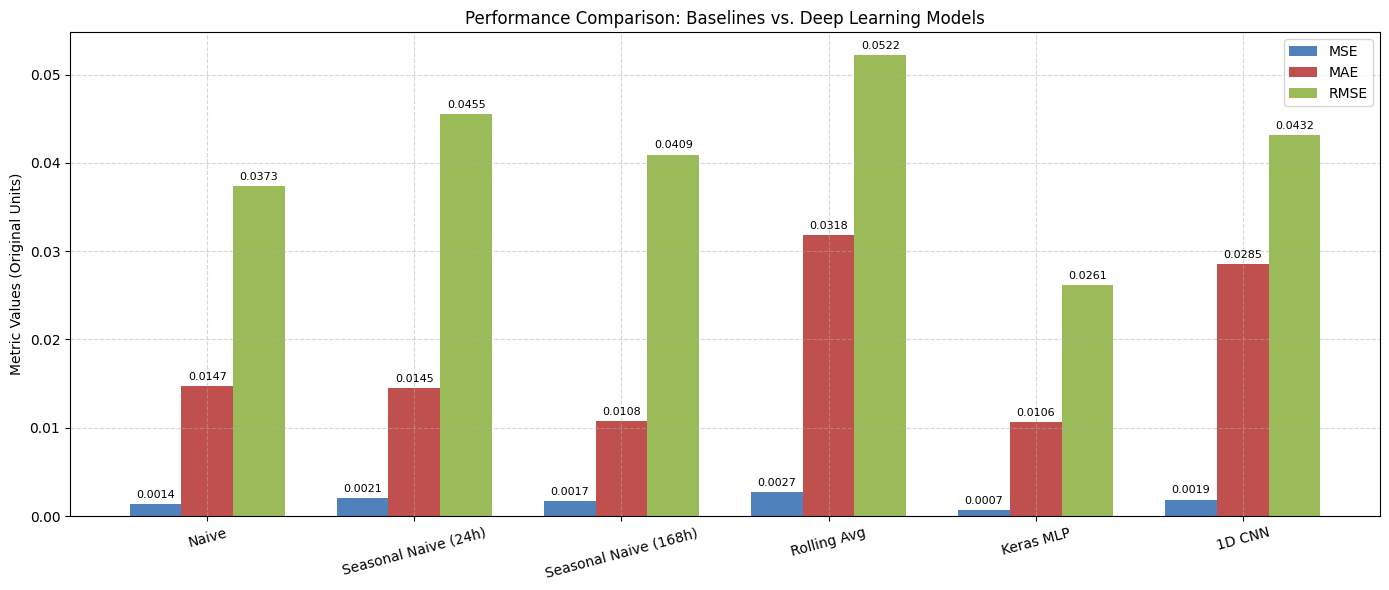

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Gather metrics for all models in original units
models = ['Naive', 'Seasonal Naive (24h)', 'Seasonal Naive (168h)', 'Rolling Avg', 'Keras MLP', '1D CNN']

# Extracting metrics from variables
mses = [
    baselines['Naive'][0],
    baselines['Seasonal Naive (24h)'][0],
    baselines['Seasonal Naive (168h)'][0],
    baselines['Rolling Average (24h)'][0],
    test_mse,
    test_mse_cnn
]
maes = [
    baselines['Naive'][1],
    baselines['Seasonal Naive (24h)'][1],
    baselines['Seasonal Naive (168h)'][1],
    baselines['Rolling Average (24h)'][1],
    test_mae,
    test_mae_cnn
]
rmses = [
    baselines['Naive'][2],
    baselines['Seasonal Naive (24h)'][2],
    baselines['Seasonal Naive (168h)'][2],
    baselines['Rolling Average (24h)'][2],
    test_rmse,
    test_rmse_cnn
]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

# Create grouping bars
rects1 = ax.bar(x - width, mses, width, label='MSE', color='#4F81BD')
rects2 = ax.bar(x, maes, width, label='MAE', color='#C0504D')
rects3 = ax.bar(x + width, rmses, width, label='RMSE', color='#9BBB59')

ax.set_ylabel('Metric Values (Original Units)')
ax.set_title('Performance Comparison: Baselines vs. Deep Learning Models')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

# Add values on top of the bars for precision
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.tight_layout()
plt.show()

### Structured Metric Summary Table

In [19]:
import pandas as pd

# Prepare data rows for all evaluated models
summary_data = {
    'Model': [
        'Naive (Best Baseline)',
        'Seasonal Naive (24h)',
        'Seasonal Naive (168h)',
        'Rolling Average (24h)',
        'Keras MLP (Lookback=168, Hidden=64, LR=0.001)',
        '1D CNN (Lookback=168, Filters=64, Kernel=3, LR=0.01)'
    ],
    'Test MSE': [
        baselines['Naive'][0],
        baselines['Seasonal Naive (24h)'][0],
        baselines['Seasonal Naive (168h)'][0],
        baselines['Rolling Average (24h)'][0],
        test_mse,
        test_mse_cnn
    ],
    'Test MAE': [
        baselines['Naive'][1],
        baselines['Seasonal Naive (24h)'][1],
        baselines['Seasonal Naive (168h)'][1],
        baselines['Rolling Average (24h)'][1],
        test_mae,
        test_mae_cnn
    ],
    'Test RMSE': [
        baselines['Naive'][2],
        baselines['Seasonal Naive (24h)'][2],
        baselines['Seasonal Naive (168h)'][2],
        baselines['Rolling Average (24h)'][2],
        test_rmse,
        test_rmse_cnn
    ],
    'Improvement vs. Best Baseline (RMSE)': [
        f'{((best_baseline_rmse - baselines["Naive"][2]) / best_baseline_rmse) * 100:.2f}%',
        f'{((best_baseline_rmse - baselines["Seasonal Naive (24h)"][2]) / best_baseline_rmse) * 100:.2f}%',
        f'{((best_baseline_rmse - baselines["Seasonal Naive (168h)"][2]) / best_baseline_rmse) * 100:.2f}%',
        f'{((best_baseline_rmse - baselines["Rolling Average (24h)"][2]) / best_baseline_rmse) * 100:.2f}%',
        f'{improv:.2f}%',
        f'{improv_cnn:.2f}%'
    ]
}

# Create DataFrame
df_summary = pd.DataFrame(summary_data)

# Render styled table
display(df_summary.style.set_caption("Summary of Traffic Forecasting Performance (sensor_0)").hide(axis='index'))

Model,Test MSE,Test MAE,Test RMSE,Improvement vs. Best Baseline (RMSE)
Naive (Best Baseline),0.001394,0.014731,0.037335,0.00%
Seasonal Naive (24h),0.002071,0.014473,0.045509,-21.89%
Seasonal Naive (168h),0.001676,0.010774,0.040939,-9.65%
Rolling Average (24h),0.002722,0.031793,0.052177,-39.75%
"Keras MLP (Lookback=168, Hidden=64, LR=0.001)",0.000682,0.010640,0.026115,30.05%
"1D CNN (Lookback=168, Filters=64, Kernel=3, LR=0.01)",0.001862,0.028502,0.043154,-15.59%


# Conclusion

The MLP performed very well showing a 30% improvement on the naive. The CNN performed surprisingly poorly, performing 15% **worse** than the naive baseline. This is unexpeted and points to errors in the setup of my CNN model, or simply an inefficient architecture. Likely using averagePooling instead of max is not helping.

One potential area of improvement is the fact I selected only one arbitrary dataset. In the future, the model could be generalized to work on any given sensor (trained on a selection of sensors). Additionally, this sensor specifically may be too repetetive or consistently low-valued, biasing the results.

